In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("e01_datos.csv")# Carga el dataset

print(data.shape)# Muestra número de filas y columnas
print(data.dtypes)# Revisa el tipo de cada variable

data.head()# Muestra los primeros datos

(183, 5)
y        float64
x1           str
x2       float64
x3       float64
grupo        str
dtype: object


,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B


## Analisis y limpieza de datos

In [3]:
print(data.isna().sum())# Cuenta valores faltantes por columna

y        0
x1       0
x2       2
x3       1
grupo    1
dtype: int64


In [4]:
print(data['grupo'].value_counts(dropna=False))# Revisa categorías de grupo

print(data['x1'].unique())# Revisa los valores de x1

grupo
A          73
B          60
C          42
a           1
 B          1
grupo_c     1
AA          1
c           1
NaN         1
b           1
D           1
Name: count, dtype: int64
<ArrowStringArray>
[ '3.745401188473625',   '9.50714306409916',  '7.319939418114051',
  '5.986584841970366', '1.5601864044243652', '1.5599452033620265',
 '0.5808361216819946',  '8.661761457749352',  '6.011150117432088',
  '7.080725777960454',
 ...
 '2.2649577519793795',  '6.451727904094499', '1.7436642900499144',
   '6.90937738102466',  '3.867353463005374',  '9.367299887367343',
 '1.3752094414599323',                '9.8',                '0.4',
                '9.5']
Length: 183, dtype: str


In [5]:
data['x1'] = data['x1'].str.replace(',', '.')# Cambia coma por punto decimal
data['x1'] = pd.to_numeric(data['x1'])# Convierte x1 a numérica

print(data['x1'].dtype)# Verificar el cambio

float64


In [6]:
data['grupo'] = data['grupo'].str.upper()# Convierte categorías a mayúsculas
data['grupo'] = data['grupo'].str.strip()# Elimina espacios

print(data['grupo'].value_counts(dropna=False))# Revisar nuevamente

grupo
A          74
B          62
C          43
GRUPO_C     1
AA          1
NaN         1
D           1
Name: count, dtype: int64


In [9]:
data['grupo'] = data['grupo'].replace({'GRUPO_C': 'C'})# Corregir error de redaccion
data['grupo'] = data['grupo'].replace({'AA': 'A'})  

In [8]:
data.loc[data['grupo'] == 'D', 'grupo'] = np.nan #Esta categoria no es valida

In [10]:
print(data.isna().sum())# Revisa faltantes antes de eliminar
print(data.shape)# Guarda referencia del tamaño anterior

data = data.dropna()# Elimina filas con información faltante

print(data.shape)# Revisa cuántas observaciones quedaron

y        0
x1       0
x2       2
x3       1
grupo    2
dtype: int64
(183, 5)
(178, 5)


Se eliminaron 5 filas ya que eran los que marcaban faltantes o categoria invalida y el uso de es informacion no era posible

In [11]:
print(data.duplicated().sum())# Cuenta observaciones completamente repetidas

data = data.drop_duplicates()# Elimina duplicados si existen

0


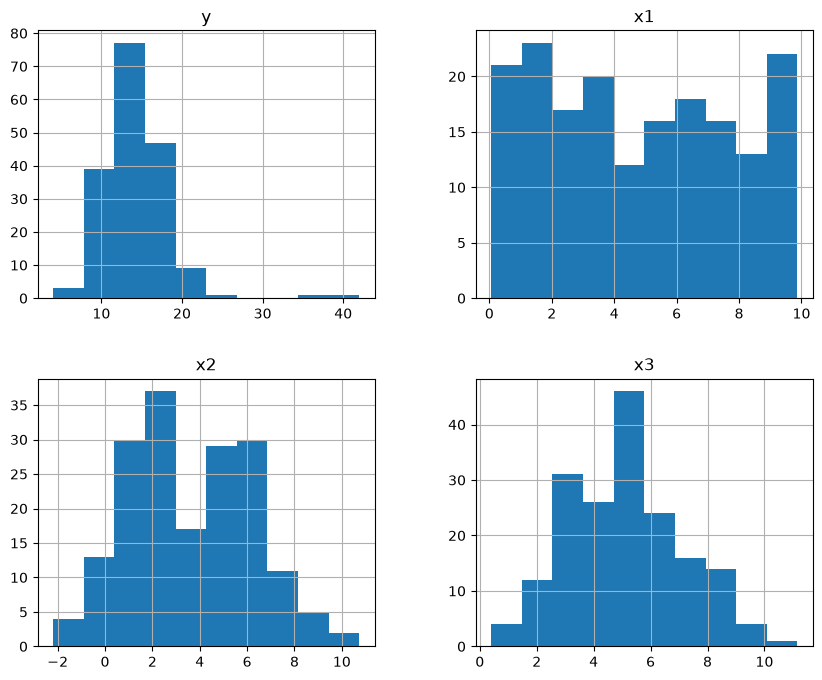

In [12]:
data.hist(figsize=(10, 8))# Genera histogramas de variables numéricas
plt.show()# Muestra las gráficas

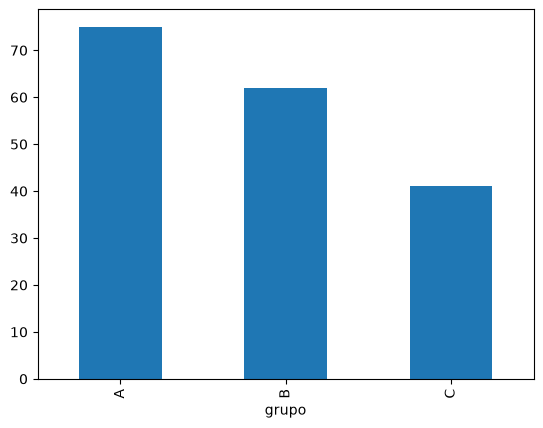

In [13]:
data['grupo'].value_counts().plot(kind='bar')# Para grupo ya que no es numeria
plt.show()    

In [17]:
numericas = data[['y', 'x1', 'x2', 'x3']]   # Selecciona variables numéricas

numericas.describe() #Estadisticos

,y,x1,x2,x3
count,178.000000,178.000000,178.000000,178.000000
mean,14.130758,4.746166,3.685684,5.063340
std,4.233002,2.966370,2.599756,2.003016
min,4.000000,0.055221,-2.194452,0.396158
25%,11.715950,2.147813,1.606102,3.518048
50%,13.634059,4.641425,3.499782,4.992027
75%,16.030766,7.294564,5.717020,6.327197
max,42.000000,9.868869,10.739239,11.157762


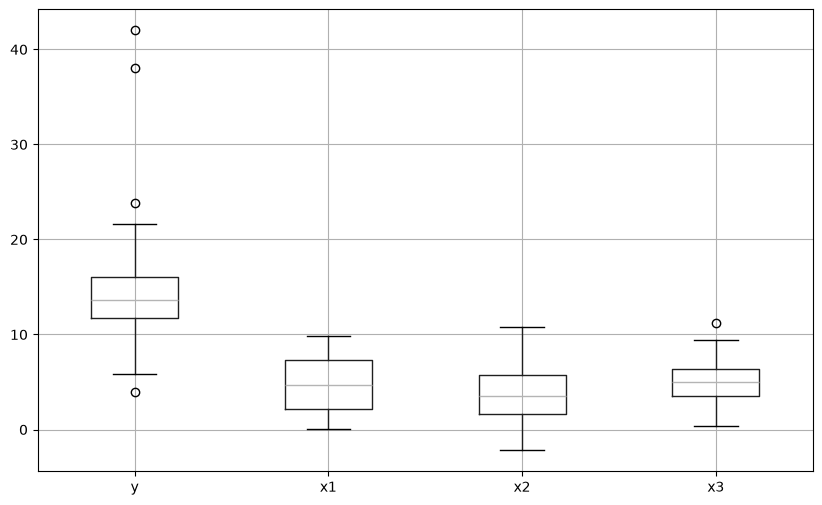

In [16]:
numericas.boxplot(figsize=(10, 6))# Busca posibles valores atípicos
plt.show()     

Los histogramas y diagramas de caja permiten observar la distribución de las variables y posibles valores atípicos.

## Modelo regresion

In [19]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

numericas = ['x1', 'x2', 'x3']   
categoricas = ['grupo']  

grupo = ColumnTransformer(
    transformers=[
        ('grupo', OneHotEncoder(drop='first'), categoricas)
    ],
    remainder='passthrough'
) # Transforma mi variable categorica a numerica sin dar peso por orden 

In [21]:
X = data[['x1', 'x2', 'x3', 'grupo']] #Defino las variables para mi modelo
y = data['y']

In [22]:
X = grupo.fit_transform(X)

In [23]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression() #Modelo de regresion lineal multiple
modelo.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 2.7 ,-2.26, 0.64, 0.23, 0.67]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.457
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[50.94,26.64,12.68, 7.07, 4.54]"


In [24]:
r2 = modelo.score(X, y)

print("R2:", r2)

R2: 0.5935012316808936


El modelo explica aproximadamente el 59.35% de la variación de y

## Residuos y pruebas de errores

In [25]:
# Predicciones y los residuos
y_pred = modelo.predict(X)
residuos = y - y_pred

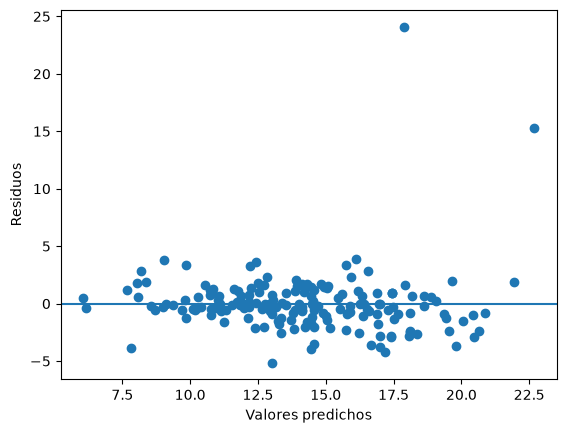

In [26]:
# Grafica de residuos

plt.scatter(y_pred, residuos)
plt.axhline(0)
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show()

Los residuos se encuentran alrededor de cero y no se observa un patrón curvo claro, por lo que no parece existir un problema importante de no linealidad. Sin embargo, se observan algunos valores alejados que se revisarán posteriormente como posibles outliers.

In [29]:
# Correlacion
DW = np.sum(np.diff(residuos)**2) / np.sum(residuos**2)

print(DW)

2.0526682466650024


Como es aproximadamente 2, no observamos un problema importante de correlación entre los errores.

In [30]:
# Colinealidad

X_num = data[['x1', 'x2', 'x3']]

for variable in X_num.columns:
    X_otros = X_num.drop(columns=variable)
    y_vif = X_num[variable]

    modelo_vif = LinearRegression()
    modelo_vif.fit(X_otros, y_vif)

    r2_vif = modelo_vif.score(X_otros, y_vif)
    vif = 1 / (1 - r2_vif)

    print(variable, "VIF:", vif)

x1 VIF: 4.499028830438657
x2 VIF: 4.499211019262727
x3 VIF: 1.0006768726857485


omo ninguno supera 5, no se considera que exista un problema importante de colinealidad.

In [33]:
# Outliers

limite = 3 * residuos.std()

outliers = data[np.abs(residuos) > limite]

print(limite)
outliers

8.096537558329594


,y,x1,x2,x3,grupo
180,42.0,9.8,8.0,5.0,A
182,38.0,9.5,9.2,8.0,B


180 y 182 osibles outliers, ya que sus residuos superan el límite de 3 desviaciones estándar. Estas observaciones presentan valores de y de 42 y 38, alejándose considerablemente de lo esperado por el modelo.

In [35]:
# High leverage

X_array = np.asarray(X)

X_leverage = np.column_stack((np.ones(len(X_array)), X_array))

H = X_leverage @ np.linalg.pinv(X_leverage.T @ X_leverage) @ X_leverage.T

leverage = np.diag(H)

limite_leverage = 2 * X_leverage.shape[1] / len(X_leverage)

print("Límite leverage:", limite_leverage)
print(np.where(leverage > limite_leverage)[0])
print(data.index[leverage > limite_leverage])

Límite leverage: 0.06741573033707865
[ 12  64  71 123 157]
Index([12, 66, 73, 126, 162], dtype='int64')


Se encontraron 5 observaciones que superan el límite de leverage de 0.0674.

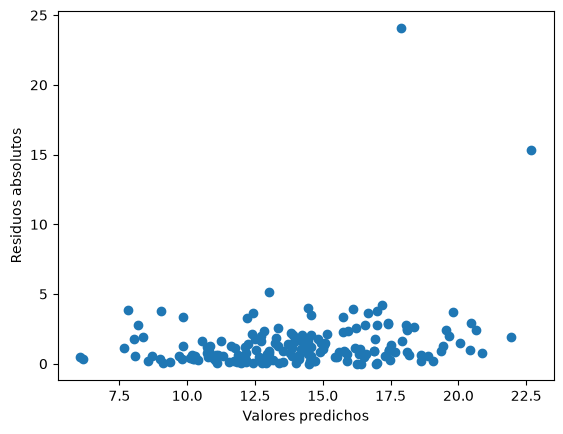

In [36]:
# Heterocedasticidad

plt.scatter(y_pred, np.abs(residuos))
plt.xlabel("Valores predichos")
plt.ylabel("Residuos absolutos")
plt.show()

No se observa un patrón claro de aumento o disminución en la dispersión de los residuos, por lo que no parece existir un problema importante de heterocedasticidad. Los dos valores más alejados corresponden a los outliers detectados anteriormente.

## Mejorar el modelo

In [37]:
# Eliminamos los outliers detectados

data_mejorado = data.drop(index=[180, 182])

print(data.shape)
print(data_mejorado.shape)

(178, 5)
(176, 5)


In [38]:
# Separamos las variables para el modelo mejorado

X_mejorado = data_mejorado[['x1', 'x2', 'x3', 'grupo']]
y_mejorado = data_mejorado['y']

X_mejorado = grupo.fit_transform(X_mejorado)

In [39]:
# Modelo sin los outliers

modelo_mejorado = LinearRegression()
modelo_mejorado.fit(X_mejorado, y_mejorado)

r2_mejorado = modelo_mejorado.score(X_mejorado, y_mejorado)

print("R2 modelo original:", r2)
print("R2 modelo mejorado:", r2_mejorado)

R2 modelo original: 0.5935012316808936
R2 modelo mejorado: 0.7653369749601319


Al eliminar los dos outliers detectados, el R² aumentó de 0.5935 a 0.7653

In [41]:
# Validación cruzada del modelo mejorado

scores_mejorado = cross_val_score(
    LinearRegression(),
    X_mejorado,
    y_mejorado,
    cv=kf,
    scoring='r2'
)

print("R2 por partición:", scores_mejorado)
print("R2 promedio:", scores_mejorado.mean())

R2 por partición: [0.71427209 0.82691724 0.72345631 0.6549451  0.77134448]
R2 promedio: 0.738187045978001


Los resultados entre las particiones son relativamente consistentes, por lo que el modelo presenta un buen desempeño fuera de los datos de entrenamiento.

## Conclusion

Primero se limpiaron los datos para poder trabajar correctamente con ellos y después se hizo el modelo de regresión. Al revisar los errores se encontraron dos outliers que estaban afectando bastante al modelo, por lo que se eliminaron y el R² mejoró de 0.5935 a 0.7653. Finalmente, con la validación cruzada se obtuvo un R² promedio de 0.7382, por lo que considero que el modelo mejorado tiene un buen ajuste y mantiene resultados similares al probarlo con diferentes partes de los datos.